<p class="hz-kicker">Week 3 · Live session</p>

# Pricing with regression

Altamar's revenue manager wants a number, not a hunch: the nightly rate a booking should carry, from its hotel, month, room and channel. Today you build that model with ready-made code, read its coefficients like a revenue manager, and say in dollars how wrong it is, and where it goes wrong.

<ul class="hz-lesson-meta"><li>4 hours</li><li>10 ideas</li><li>Runs in your browser</li><li>Case: a first model</li></ul>

**Before anything else:** run the cell below. On this site, press its **Run** button (in Google Colab, the ▶ next to it, or Shift + Enter). It loads today's tools and two small helpers we use later. You don't need to read it.

In [1]:
# Setup: tools for today. Run this cell first; you don't need to read it.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

DATA = "https://raw.githubusercontent.com/hizocar/mba-business-analytics-1/main/docs/datasets/"
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
HOTELS = ["Santiago", "Viña del Mar", "Puerto Varas"]
pd.set_option("display.width", 120)
sns.set_theme(style="whitegrid")

# Every category of each text column. The FIRST one is the reference: its coefficient is 0,
# and the model measures the others against it.
LEVELS = {
    "hotel": ["Santiago", "Viña del Mar", "Puerto Varas"],
    "room_type": ["Standard", "Superior", "Suite"],
    "channel": ["Direct", "Online travel agency", "Corporate", "Travel agent"],
    "customer_type": ["Leisure", "Business", "Group"],
    "deposit": ["No deposit", "Non-refundable"],
    "country": ["Chile", "Argentina", "Brazil", "United States", "Europe", "Other", "Unknown"],
    "arrival_month": list(range(1, 13)),
}

def make_X(data, features):
    """Turn the chosen columns into numbers: one 0/1 column per category, minus the reference."""
    parts = []
    for col in features:
        if col in LEVELS:
            values = pd.Series(pd.Categorical(data[col], categories=LEVELS[col]), index=data.index)
            parts.append(pd.get_dummies(values, prefix=col, drop_first=True, dtype="int64"))
        else:
            parts.append(data[[col]])
    return pd.concat(parts, axis=1)

def scores(name, actual, predicted):
    """One row of a results table: the typical error in USD per night, and R²."""
    mae = mean_absolute_error(actual, predicted)
    return {"model": name, "MAE (USD/night)": round(mae, 1),
            "MAE as % of avg rate": f"{mae / actual.mean():.0%}", "R²": round(r2_score(actual, predicted), 3)}

print("Ready: tools loaded.")

Ready: tools loaded.


## <span class="hz-step-n">01</span> Previously at Altamar

In week 2 we cleaned the bookings: one spelling per hotel and channel, no free rooms or typed-in extra zeros, no impossible dates. And the clean data told a story: **the rate depends on the hotel, the season and the room**, and each hotel has its own seasons.

Now revenue management asks for more than a story. When a booking request comes in, they want **an estimate of the right rate for it**, one that combines everything we know about the booking at once. That estimate is a **model**.

Load the 5,964 clean bookings and print the average rate for each hotel and room type. Look at how far apart the cells are.

In [2]:
df = pd.read_csv(DATA + "altamar_bookings_clean.csv")
df["arrival_month"] = pd.to_datetime(df["arrival_date"]).dt.month    # 1 = January … 12 = December
print(f"{len(df):,} bookings · average rate USD {df['adr'].mean():.0f} per night\n")
table = df.pivot_table(index="hotel", columns="room_type", values="adr", aggfunc="mean")
print(table.reindex(HOTELS)[["Standard", "Superior", "Suite"]].round(0).to_string())

5,964 bookings · average rate USD 127 per night

room_type     Standard  Superior  Suite
hotel                                  
Santiago          85.0     109.0  156.0
Viña del Mar     117.0     154.0  232.0
Puerto Varas     133.0     171.0  257.0


The same rates by arrival month, one line per hotel. Look for the months where the lines cross.

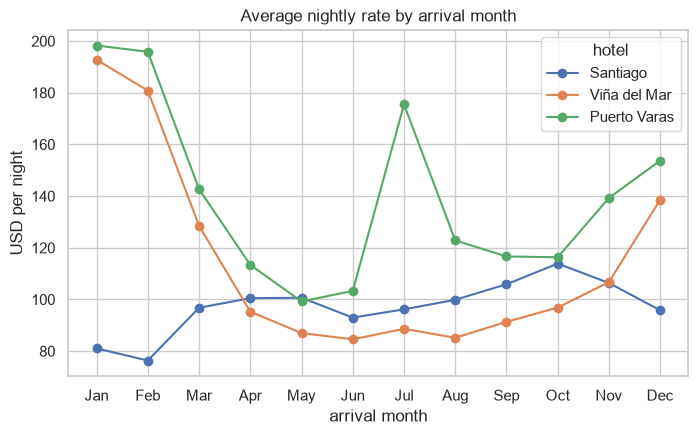

In [3]:
monthly = df.pivot_table(index="arrival_month", columns="hotel", values="adr", aggfunc="mean")[HOTELS]
ax = monthly.plot(figsize=(8, 4.5), marker="o")
ax.set_xticks(range(1, 13), MONTHS)
ax.set(title="Average nightly rate by arrival month", xlabel="arrival month", ylabel="USD per night")
plt.show()

**Business takeaway:** a Suite costs about twice a Standard room, Puerto Varas and Viña charge more than Santiago, and summer (January and February) is peak season at the beach and the lake but the *quiet* season in Santiago. A good rate estimate has to weigh all of this at once, for every booking. That is the job of today's model.

## <span class="hz-step-n">02</span> A model is a recipe

Remember week 1's picture: a model is a **recipe** that turns inputs into an answer. Today the answer is a number, the **predicted rate**, so this is **regression**.

The recipe is not written by us: the model **learns it from past bookings**, where we know both the inputs and the rate the guest paid. Then it applies the recipe to a new request whose rate is still unknown.

Which inputs? Only what we **know when the guest asks for a price**: hotel, arrival month, room, channel, nights, how far ahead they book, how many guests.

Look at one past booking split into its two halves: what the model sees, and the answer it learns from.

In [4]:
booking = df.iloc[0]
inputs = ["hotel", "arrival_month", "room_type", "channel", "nights", "lead_time_days", "adults"]
print("What the model sees (known when the guest asks for a price):")
print(booking[inputs].to_string())
print(f"\nThe answer it learns from: adr = USD {booking['adr']:.2f} per night")

What the model sees (known when the guest asks for a price):
hotel                     Viña del Mar
arrival_month                        1
room_type                     Superior
channel           Online travel agency
nights                               3
lead_time_days                      92
adults                               2

The answer it learns from: adr = USD 202.58 per night


**What we must not feed the recipe:**

| Column | Why not |
|---|---|
| `adr` | It is the answer. A model that sees it scores perfectly and is useless. |
| `booking_id` | A label, not a fact about the stay. Booking AH-200457 is not "bigger" than AH-200001. |
| `booking_date`, `arrival_date` | Text like "2025-02-14" is not a number. We keep what matters, the **month** (`arrival_month`). |
| `canceled` | We only know it *after* the booking. For a new request it does not exist yet. |

**Watch out:** an input that secretly contains the answer is called **leakage**. It makes a model look brilliant in testing and fail on the first real booking.

<div class="hz-widget" data-widget="quiz">
<script type="application/json">{"q": "The revenue team wants to predict the rate of <em>new</em> booking requests. Which column should <strong>not</strong> be an input?", "options": ["room_type", "lead_time_days", "canceled", "arrival_month"], "answer": 2, "why": "Whether a booking is cancelled is only known later, so it does not exist when we quote a new request. Room, lead time and month are all known at the moment the guest asks for a price.", "code": false}</script>
</div>

## <span class="hz-step-n">03</span> Train and test: a sealed envelope

How do we know if the recipe is any good? Not by asking it about bookings it learned from: that is an exam where the student has seen the answers.

So before learning anything, we **split** the bookings. Three quarters go to the **training set**: the model learns from these. One quarter goes into a **sealed envelope**, the **test set**, which we open only once, at the end, to measure how wrong the model is on bookings it has never seen. Press **Play**.

<div class="hz-widget" data-widget="train-test-split">
<p>▶ Interactive simulator: <a href="https://hizocar.github.io/mba-business-analytics-1/sessions/Session_3_Live/">open this session on the course website</a> to use it.</p>
</div>

Split the real bookings: 75% to learn from, 25% sealed (`test_size=0.25`). `random_state=42` makes the shuffle the same every time, for everyone in the class. Check that both parts look alike.

In [5]:
train, test = train_test_split(df, test_size=0.25, random_state=42)
print(f"Training set: {len(train):,} bookings · test set: {len(test):,} bookings (sealed)\n")
mix = pd.DataFrame({"training set": train["hotel"].value_counts(normalize=True),
                    "test set": test["hotel"].value_counts(normalize=True)}).reindex(HOTELS)
print((mix * 100).round(1).astype(str).add(" %").to_string())
print(f"\nAverage rate: USD {train['adr'].mean():.1f} in training, USD {test['adr'].mean():.1f} in test")

Training set: 4,473 bookings · test set: 1,491 bookings (sealed)

             training set test set
hotel                             
Santiago           41.4 %   40.0 %
Viña del Mar       34.0 %   33.7 %
Puerto Varas       24.6 %   26.4 %

Average rate: USD 127.4 in training, USD 127.2 in test


**Business takeaway:** the two sets have the same mix of hotels and almost the same average rate, so the test set is a fair stand-in for "next month's bookings". From now on, the model learns **only** from `train`; `test` stays sealed until step 08.

## <span class="hz-step-n">04</span> Categories become numbers

A linear model can multiply `nights` by a number. It cannot multiply `"Suite"`. So each text column becomes a few **0/1 columns**, one per category: `room_type_Suite` is 1 for suites and 0 otherwise. This is called **one-hot encoding**, or making **dummies**.

One category per column gets no 0/1 column at all: the **reference**. A row of zeros means "reference", and every other category is measured **against it**. Encode the six bookings below, then try `drop_first=True`.

<div class="hz-widget" data-widget="one-hot">
<p>▶ Interactive simulator: <a href="https://hizocar.github.io/mba-business-analytics-1/sessions/Session_3_Live/">open this session on the course website</a> to use it.</p>
</div>

See it on six real bookings: the text column next to its 0/1 columns, first with all three, then without the reference.

In [6]:
sample = df[["hotel", "room_type", "adr"]].groupby("room_type").head(2).sort_index()   # two of each room
rooms = pd.get_dummies(sample["room_type"], prefix="room_type", dtype="int64")
print(pd.concat([sample, rooms], axis=1).to_string(), "\n")
print("With drop_first=True, Standard (first alphabetically) becomes the reference:")
print(pd.get_dummies(sample["room_type"], prefix="room_type", drop_first=True, dtype="int64").to_string())

           hotel room_type     adr  room_type_Standard  room_type_Suite  room_type_Superior
0   Viña del Mar  Superior  202.58                   0                0                   1
1       Santiago  Standard  115.22                   1                0                   0
2   Viña del Mar  Standard   68.57                   1                0                   0
3   Viña del Mar  Superior  133.13                   0                0                   1
9       Santiago     Suite  177.19                   0                1                   0
10      Santiago     Suite  167.53                   0                1                   0 

With drop_first=True, Standard (first alphabetically) becomes the reference:
    room_type_Suite  room_type_Superior
0                 0                   1
1                 0                   0
2                 0                   0
3                 0                   1
9                 1                   0
10                1                  

We **choose the references** so the coefficients read naturally for a revenue manager: "compared with a Standard room, booked direct, at Santiago, in January".

| Column | Reference |
|---|---|
| `hotel` | Santiago |
| `room_type` | Standard |
| `channel` | Direct |
| `customer_type` | Leisure |
| `arrival_month` | 1 (January) |
| `deposit`, `country` | No deposit, Chile |

The Setup cell has a helper, `make_X`, that does the encoding for every text column with these references. Here it is on four bookings.

In [7]:
print(make_X(df.head(4), ["hotel", "room_type", "nights"]).to_string())

   hotel_Viña del Mar  hotel_Puerto Varas  room_type_Superior  room_type_Suite  nights
0                   1                   0                   1                0       3
1                   0                   0                   0                0       2
2                   1                   0                   0                0       5
3                   1                   0                   1                0       6


Read the first row: a 0 in both hotel columns means **Santiago**; a 0 in both room columns means **Standard**. Numbers like `nights` pass through unchanged.

<div class="hz-widget" data-widget="quiz">
<script type="application/json">{"q": "With Standard as the reference room, how does the table show a booking for a <strong>Standard</strong> room?", "options": ["room_type_Standard = 1", "room_type_Superior = 0 and room_type_Suite = 0", "room_type_Superior = 1 and room_type_Suite = 1", "It is left out of the table"], "answer": 1, "why": "The reference has no column of its own: all zeros in the room columns means Standard. That is why every room coefficient reads as “USD more (or less) than a Standard room”.", "code": false}</script>
</div>

## <span class="hz-step-n">05</span> The best line

How does the model pick its numbers? Start with one input and one picture. At Viña del Mar, busy months charge more. Draw any line through the twelve months: each month misses it by some dollars (a **residual**). **Least squares** squares every miss and picks the line with the **smallest total**.

Squaring has a consequence a manager should know: a miss of USD 40 counts **four times** as much as a miss of USD 20. Move the line yourself, then press **Fit least squares**.

<div class="hz-widget" data-widget="least-squares">
<p>▶ Interactive simulator: <a href="https://hizocar.github.io/mba-business-analytics-1/sessions/Session_3_Live/">open this session on the course website</a> to use it.</p>
</div>

The same picture in code. `LinearRegression` finds the slope and intercept that the simulator found. (Here we use all bookings, because it only illustrates the idea; the real model in step 06 learns from `train` only.)

Slope: USD 0.61 per extra booking, so 10 more bookings in a month ≈ USD 6 higher rate


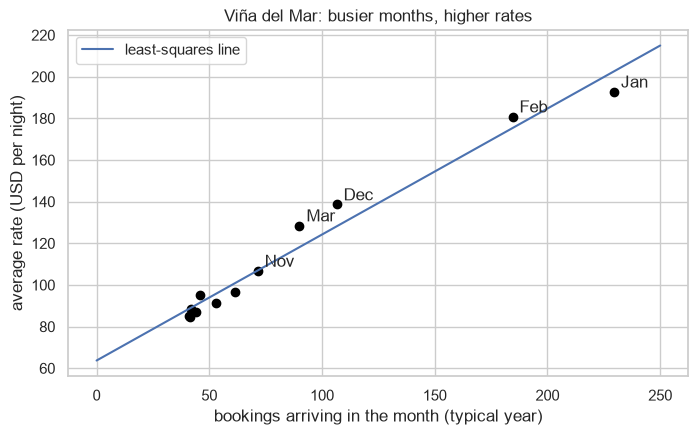

In [8]:
vina = df[df["hotel"] == "Viña del Mar"]
months = vina.groupby("arrival_month").agg(bookings=("adr", "size"), rate=("adr", "mean"))
months["bookings"] = months["bookings"] / 2           # two years of data: bookings in a typical year
line = LinearRegression().fit(months[["bookings"]], months["rate"])
print(f"Slope: USD {line.coef_[0]:.2f} per extra booking, so 10 more bookings in a month ≈ USD {10 * line.coef_[0]:.0f} higher rate")
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(months["bookings"], months["rate"], color="black")
for m, row in months[months["bookings"] > 65].iterrows():     # label the busy months
    ax.annotate(MONTHS[m - 1], (row["bookings"], row["rate"]), xytext=(5, 3), textcoords="offset points")
grid = pd.DataFrame({"bookings": np.linspace(0, 250, 50)})
ax.plot(grid["bookings"], line.predict(grid), label="least-squares line")
ax.set(title="Viña del Mar: busier months, higher rates", xlabel="bookings arriving in the month (typical year)", ylabel="average rate (USD per night)")
ax.legend(); plt.show()

**Business takeaway:** the slope is a sentence: *every 10 extra bookings in a month go with about USD 6 more per night*. The real model does exactly this, but with **36 inputs at once**: it finds one number per input so that the total squared miss over 4,473 training bookings is as small as possible.

☕ **Break (10 minutes).** In the second block we build Altamar's rate model, read it like a revenue manager, measure its error in dollars, and find where it fails.

## <span class="hz-step-n">06</span> One model for every booking

Now the full recipe. We give the model every input known when a guest asks for a price, with the **month as twelve categories** (`arrival_month`), because seasons do not go up in a straight line from January to December.

Three steps, the same in every project: **choose inputs → encode them → fit on the training set**.

Choose the inputs, encode training and test the same way, and fit `LinearRegression` on the training bookings only.

In [9]:
FEATURES = ["hotel", "arrival_month", "room_type", "channel", "customer_type", "nights", "weekend_nights",
            "lead_time_days", "adults", "children", "deposit", "repeat_guest", "previous_cancellations",
            "special_requests", "parking", "country"]
X_train, X_test = make_X(train, FEATURES), make_X(test, FEATURES)
y_train, y_test = train["adr"], test["adr"]
model = LinearRegression().fit(X_train, y_train)
print(f"{len(FEATURES)} inputs became {X_train.shape[1]} number columns.")
print(f"The model learned {X_train.shape[1]} coefficients and an intercept from {len(X_train):,} bookings.")

16 inputs became 36 number columns.
The model learned 36 coefficients and an intercept from 4,473 bookings.


Open the envelope a crack: predict six test bookings the model has never seen, next to the rate they actually paid.

In [10]:
compare = test[["hotel", "arrival_month", "room_type", "channel", "adr"]].head(6).copy()
compare["predicted"] = model.predict(X_test.head(6)).round(1)
compare["miss (USD)"] = (compare["adr"] - compare["predicted"]).round(1)
print(compare.to_string(index=False))

       hotel  arrival_month room_type              channel    adr  predicted  miss (USD)
Viña del Mar             11  Superior               Direct 139.00      145.8        -6.8
Puerto Varas             11  Standard            Corporate 108.58      109.4        -0.8
Viña del Mar             12  Standard Online travel agency 113.45      118.3        -4.8
Viña del Mar              5  Standard               Direct 112.24       96.0        16.2
Puerto Varas              8  Superior               Direct 135.34      148.8       -13.5
Puerto Varas              7  Standard               Direct 153.98      139.7        14.3


Some predictions land within a dollar, others miss by USD 15 or more. A positive miss means the guest **paid more** than the model predicted: the model would have **underpriced** the room. Before asking how wrong it is on average (step 08), let's open the recipe.

## <span class="hz-step-n">07</span> Reading the coefficients like a revenue manager

Each coefficient is in **USD per night**. For a category, it is the difference **against the reference**, everything else equal. For a number, it is the change **per unit** (per night, per day booked ahead, per adult).

The **intercept** is the starting point: a Standard room booked direct at Santiago in January, before adding anything else.

Print the intercept and the fifteen largest coefficients, biggest effect first.

In [11]:
coefs = pd.Series(model.coef_, index=X_train.columns).round(1)
print(f"Intercept: USD {model.intercept_:.1f}\n")
print(coefs.sort_values(key=abs, ascending=False).head(15).to_string())

Intercept: USD 132.8

room_type_Suite         95.0
arrival_month_6        -69.9
arrival_month_5        -67.1
arrival_month_8        -65.8
arrival_month_4        -63.6
arrival_month_9        -59.7
arrival_month_10       -55.7
arrival_month_11       -53.0
arrival_month_3        -50.7
arrival_month_7        -45.3
arrival_month_12       -42.8
hotel_Puerto Varas      41.0
room_type_Superior      31.1
hotel_Viña del Mar      20.8
channel_Travel agent   -19.5


The same coefficients as a picture, without the months (step 09 looks at them) and the countries (all small). Orange bars raise the rate, blue bars lower it.

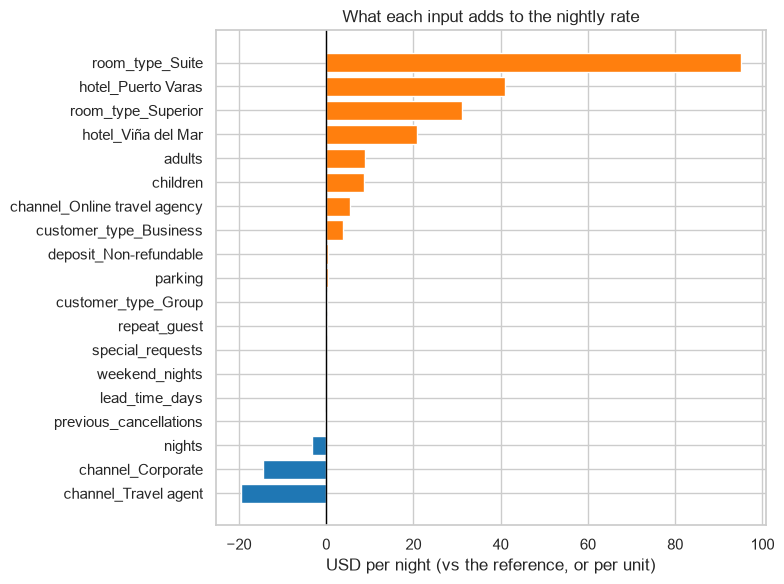

In [12]:
show = coefs[~coefs.index.str.startswith(("arrival_month", "country"))].sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(show.index, show.values, color=np.where(show.values > 0, "tab:orange", "tab:blue"))
ax.axvline(0, color="black", lw=1)
ax.set(title="What each input adds to the nightly rate", xlabel="USD per night (vs the reference, or per unit)")
plt.tight_layout(); plt.show()

Translate them into sentences a revenue manager would use.

In [13]:
c = coefs
print(f"A suite adds about USD {c['room_type_Suite']:.0f} per night over a Standard room; a Superior about USD {c['room_type_Superior']:.0f}.")
print(f"Puerto Varas is about USD {c['hotel_Puerto Varas']:.0f} above Santiago; Viña del Mar about USD {c['hotel_Viña del Mar']:.0f}.")
print(f"Corporate rates are about USD {-c['channel_Corporate']:.0f} lower than direct; travel agents about USD {-c['channel_Travel agent']:.0f} lower.")
print(f"Online travel agency bookings pay about USD {c['channel_Online travel agency']:.0f} more than direct ones.")
print(f"Each extra night lowers the nightly rate by about USD {-c['nights']:.1f}; each extra adult adds about USD {c['adults']:.0f}.")
print(f"Each weekend night adds USD {c['weekend_nights']:.1f}: almost nothing. Keep that in mind for step 09.")

A suite adds about USD 95 per night over a Standard room; a Superior about USD 31.
Puerto Varas is about USD 41 above Santiago; Viña del Mar about USD 21.
Corporate rates are about USD 14 lower than direct; travel agents about USD 20 lower.
Online travel agency bookings pay about USD 6 more than direct ones.
Each extra night lowers the nightly rate by about USD 3.3; each extra adult adds about USD 9.
Each weekend night adds USD 0.0: almost nothing. Keep that in mind for step 09.


**Watch out: average effects, not causes.** "Corporate rates are USD 14 lower" describes the bookings we had, everything else equal. It does **not** promise that moving a corporate client to the direct channel earns USD 14 more: that client might not book at all. And "everything else equal" only covers the inputs we gave the model.

Build a booking from these numbers yourself. The coefficients below are copied, rounded, from the model you just fitted.

<div class="hz-widget" data-widget="coef-explorer">
<p>▶ Interactive simulator: <a href="https://hizocar.github.io/mba-business-analytics-1/sessions/Session_3_Live/">open this session on the course website</a> to use it.</p>
</div>

<div class="hz-widget" data-widget="quiz">
<script type="application/json">{"q": "The coefficient of <code>channel_Corporate</code> is about −14. The sales director says: “if we move every corporate client to direct booking, we earn USD 14 more per night from each.” What is the problem?", "options": ["Nothing: that is exactly what the coefficient means", "The coefficient describes an average difference in past bookings; it does not say what clients would do if we changed their channel", "The coefficient is in percent, not in dollars", "Coefficients only apply to the training set, never to new bookings"], "answer": 1, "why": "A regression coefficient is an association, everything else in the model being equal. Corporate clients get lower rates <em>because</em> of an agreement; without it, they might book elsewhere. Changing the channel is a business decision the data alone cannot price.", "code": false}</script>
</div>

## <span class="hz-step-n">08</span> How wrong are we?

Time to open the sealed envelope. Three numbers, all on the **test set**:

- **MAE** (mean absolute error): the typical miss, in **USD per night**. The number to give a manager.
- **MAE as a % of the average rate**: is USD 20 a lot? For a USD 127 room, yes and no.
- **R²**: the share of the differences between rates that the model explains. 1 is perfect; 0 is no better than quoting the average to everyone.

Drag the misses below and watch the three numbers react.

<div class="hz-widget" data-widget="error-metrics">
<p>▶ Interactive simulator: <a href="https://hizocar.github.io/mba-business-analytics-1/sessions/Session_3_Live/">open this session on the course website</a> to use it.</p>
</div>

Score the model on the training and the test set, next to a **baseline** that a person could compute in a spreadsheet: quote each hotel's average rate to every booking. A model is only worth using if it beats the baseline.

In [14]:
hotel_average = train.groupby("hotel")["adr"].mean()
predicted_test = model.predict(X_test)
results = pd.DataFrame([
    scores("Baseline: the hotel's average rate (test)", y_test, test["hotel"].map(hotel_average)),
    scores("Linear model, training set", y_train, model.predict(X_train)),
    scores("Linear model, test set", y_test, predicted_test),
])
print(results.to_string(index=False))
mae = mean_absolute_error(y_test, predicted_test)
print(f"\nOn bookings it has never seen, the model's rate is typically off by USD {mae:.0f} per night,")
print(f"about {mae / y_test.mean():.0%} of the average rate (USD {y_test.mean():.0f}).")

                                    model  MAE (USD/night) MAE as % of avg rate    R²
Baseline: the hotel's average rate (test)             35.8                  28% 0.197
               Linear model, training set             20.1                  16% 0.740
                   Linear model, test set             20.5                  16% 0.738

On bookings it has never seen, the model's rate is typically off by USD 20 per night,
about 16% of the average rate (USD 127).


**Reading the results:**

- **It beats the baseline clearly:** a typical miss of USD 20 instead of USD 36, and R² 0.74 instead of 0.20.
- **Training and test are almost the same** (MAE 20.1 vs 20.5). The model did not memorize its training bookings; we can expect about the same error next month.
- **But USD 20 is 16% of the average rate.** Good enough to suggest a starting rate or to flag a quote that looks far off; not good enough to set peak-season suite prices on its own.

<div class="hz-widget" data-widget="quiz">
<script type="application/json">{"q": "A colleague's model has a typical error (MAE) of USD 5 on the training set and USD 31 on the test set. Ours has USD 20 and USD 20. Which model should revenue management use?", "options": ["The colleague's: USD 5 is the best number in the table", "Ours: its test error is lower, and train ≈ test means it will behave the same on new bookings", "Either: the training error is what matters", "Neither: a model must have zero error on the training set"], "answer": 1, "why": "The test set is the only honest exam. USD 5 on training and USD 31 on test is the signature of <strong>overfitting</strong>: the model memorized its training bookings and is worse on new ones.", "code": false}</script>
</div>

## <span class="hz-step-n">09</span> Where the line fails

An average error hides *where* the model is wrong. If the misses were random, there would be nothing to fix. If they follow a **pattern**, the model is missing something a manager would recognise.

Plot the actual rate of every test booking against the model's prediction. Points on the diagonal are perfect; look at the most expensive bookings, top right.

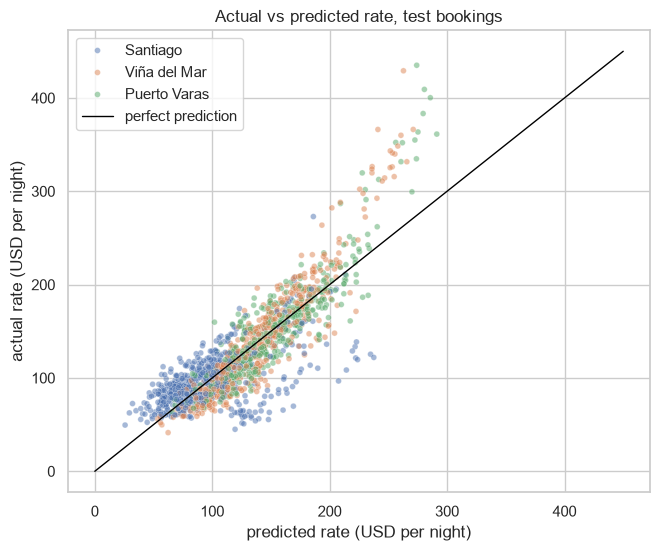

Test bookings that paid over USD 300 a night: 32.
Test bookings the model priced over USD 300: 0.


In [15]:
view = test.assign(predicted=predicted_test, miss=y_test - predicted_test)
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.scatterplot(data=view, x="predicted", y="adr", hue="hotel", hue_order=HOTELS, alpha=0.5, s=18, ax=ax)
ax.plot([0, 450], [0, 450], color="black", lw=1, label="perfect prediction")
ax.set(title="Actual vs predicted rate, test bookings", xlabel="predicted rate (USD per night)", ylabel="actual rate (USD per night)")
ax.legend(); plt.show()
print(f"Test bookings that paid over USD 300 a night: {(view['adr'] > 300).sum()}.")
print(f"Test bookings the model priced over USD 300: {(view['predicted'] > 300).sum()}.")

**The model misses the peaks.** The most expensive bookings sit far above the diagonal: a line that adds fixed amounts never reaches the top rates of peak-season suites. And there is a cloud of Santiago bookings priced too high. When and where?

Average miss for each hotel and arrival month (actual − predicted). Red cells: the model **underprices**; blue cells: it **overprices**.

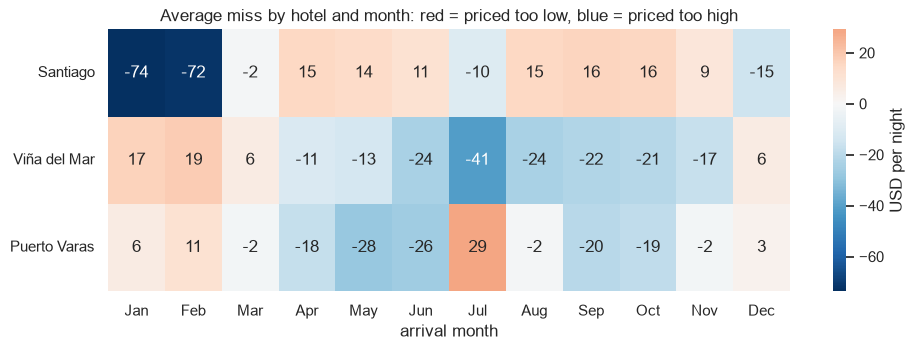

In [16]:
heat = view.pivot_table(index="hotel", columns="arrival_month", values="miss", aggfunc="mean").reindex(HOTELS)
heat.columns = MONTHS
fig, ax = plt.subplots(figsize=(11, 3.4))
sns.heatmap(heat, annot=True, fmt=".0f", cmap="RdBu_r", center=0, cbar_kws={"label": "USD per night"}, ax=ax)
ax.set(title="Average miss by hotel and month: red = priced too low, blue = priced too high", xlabel="arrival month", ylabel="")
ax.tick_params(axis="y", rotation=0)
plt.show()

**A systematic pattern, not noise.** The model has **one** January effect, **one** July effect, shared by all three hotels. It learned that January is expensive (true at the beach and the lake) and charges it to Santiago too, where January is quiet: about USD 70 too much per night. July is a peak only in Puerto Varas, so the model underprices it there and overprices it in Viña. Seasons **differ by hotel**, and a model that adds one month effect for everyone cannot draw that. Switch hotels below.

<div class="hz-widget" data-widget="season-misfit">
<p>▶ Interactive simulator: <a href="https://hizocar.github.io/mba-business-analytics-1/sessions/Session_3_Live/">open this session on the course website</a> to use it.</p>
</div>

Does giving the model better inputs help? Compare the month as a **single number** (1 to 12, so the model can only draw a slope through the year) with the month as **twelve categories**.

In [17]:
features_num = [f if f != "arrival_month" else "month_number" for f in FEATURES]
train_num, test_num = train.assign(month_number=train["arrival_month"]), test.assign(month_number=test["arrival_month"])
model_num = LinearRegression().fit(make_X(train_num, features_num), y_train)
results = pd.DataFrame([
    scores("Month as a number (1 to 12)", y_test, model_num.predict(make_X(test_num, features_num))),
    scores("Month as 12 categories", y_test, predicted_test),
])
print(results.to_string(index=False))

                      model  MAE (USD/night) MAE as % of avg rate    R²
Month as a number (1 to 12)             26.9                  21% 0.621
     Month as 12 categories             20.5                  16% 0.738


**Better inputs help, but a line has limits.** Treating the month as categories lifts R² from about 0.62 to 0.74 and cuts the typical miss from USD 27 to USD 20. But no choice of inputs lets a model that *adds one effect per input* learn "January is peak at the beach and quiet in Santiago", or "suites go up more than other rooms in peak season". Those are **interactions** and **curves**.

**Coming in week 5:** decision trees learn "Puerto Varas in July" on their own, and the typical miss drops well below USD 20.

<div class="hz-widget" data-widget="quiz">
<script type="application/json">{"q": "In the heatmap, Santiago bookings in January are priced about USD 70 too high on average. What is the best explanation?", "options": ["Santiago guests in January negotiated discounts the data does not show", "The test set has too few Santiago bookings to say anything", "The model has one January effect for all hotels, learned mostly from the beach and the lake, where January is peak season", "Least squares always overprices the cheapest hotel"], "answer": 2, "why": "The month coefficients are shared by the three hotels. January is peak season in Viña and Puerto Varas, so the January effect is large, and the model applies it to Santiago, where January is quiet. The misses follow a pattern: the model is missing an interaction between hotel and month.", "code": false}</script>
</div>

## <span class="hz-step-n">10</span> Case clinic: a first model

This week's step of the [applied case](https://hizocar.github.io/mba-business-analytics-1/case/case/) is **a first model**: a linear model evaluated on test data. In the next 40 minutes, with your team, in the [case toolkit](https://hizocar.github.io/mba-business-analytics-1/case/Case_Toolkit/) (in Colab):

1. **Run sections 05 Train/test split and baseline and 06 Linear model** with your column to predict: **linear regression** for a number (TalentCo's salary), **logistic regression** for yes/no (FinTrust's default). Keep 25% of the rows as the sealed test set (`test_size=0.25`, `random_state=42`), as we did.
2. **Check what goes in.** Remove IDs, raw dates and anything only known *after* the outcome (leakage).
3. **Read the error in business units:** "our salary estimate is typically off by USD …, about …% of the average salary". For classification, write down the accuracy and compare it with the "predict the most common answer" baseline; week 4 gives you better metrics.
4. **Write three coefficient sentences** like the ones in step 07, each with its reference category.

**What to bring next week:** the test error of your first model next to a baseline, in one sentence a manager understands, and one place where you suspect the line is wrong (a group, a season, a range of values).

**Before next week:** do the lab, [A rate simulator](https://hizocar.github.io/mba-business-analytics-1/sessions/Session_3_Lab/), and its graded quiz. In week 4, [Predicting cancellations](https://hizocar.github.io/mba-business-analytics-1/sessions/Session_4_Live/), the answer becomes yes or no, and the question becomes how many rooms to oversell.